# Module 8 Lab 2: AI-Assisted Clustering (Life-Cycle Savings)
**Name:** Roey Kadur 

**Goal:** learn one clustering method with AI, keep the country names out of the model features, and verify one cluster claim with my own calculation.

**Dataset:** 50 countries with five numeric measurements from the 1960–1970 life-cycle savings data. The source CSV spells the country identifier column `Contry`; I keep that source name in code so the notebook matches the file.

**Portfolio repository:** https://github.com/roee0910/cs82a-portfolio

## Reading and method note

The course preview link for the textbook was not accessible in this session, so I cannot claim to have checked the exact Hands-On Problem wording or its code listing. I use the assignment summary provided here and cross-check the method with the scikit-learn documentation. In plain language, clustering groups rows that are close on the numeric features; it does not use a known answer label. Here, K-means uses standardized measurements so `dpi` (measured in much larger numbers) does not automatically outweigh percentage variables. The textbook-code comparison remains unchecked.

## Step 1: Load the data

Place `lifecyclesavings.csv` beside this notebook, or upload it when prompted in Colab.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_FILE = "lifecyclesavings.csv"
if not os.path.exists(DATA_FILE):
    try:
        from google.colab import files
        files.upload()
    except ImportError as exc:
        raise FileNotFoundError(
            "Place lifecyclesavings.csv in the notebook folder before running."
        ) from exc

df = pd.read_csv(DATA_FILE)
print("Loaded rows and columns:", df.shape)
print("Columns:", df.columns.tolist())
df.head()

Loaded rows and columns: (50, 6)
Columns: ['Contry', 'sr', 'pop15', 'pop75', 'dpi', 'ddpi']


,Contry,sr,pop15,pop75,dpi,ddpi
0,Australia,11.43,29.35,2.87,2329.68,2.87
1,Austria,12.07,23.32,4.41,1507.99,3.93
2,Belgium,13.17,23.80,4.43,2108.47,3.82
3,Bolivia,5.75,41.89,1.67,189.13,0.22
4,Brazil,12.88,42.19,0.83,728.47,4.56


## Step 2: Hand-computed baseline (before asking AI)

I first record the shape, missing values, and means without using a clustering result. `Contry` is a text identifier, not a measurement, so it has no meaningful numeric mean. The five numeric column means are calculated directly from the full dataset.

In [2]:
numeric_cols = df.select_dtypes(include="number").columns.tolist()
missing_counts = df.isna().sum()
column_means = df[numeric_cols].mean()

print("Shape (rows, columns):", df.shape)
print("\nMissing values per column:")
print(missing_counts.to_string())
print("\nMean of each numeric column:")
print(column_means.round(4).to_string())
print("\nContry: text country identifier; numeric mean: not applicable")

# Baseline checks against the supplied file.
assert df.shape == (50, 6), f"Unexpected shape: {df.shape}"
assert int(missing_counts.sum()) == 0, "Unexpected missing values"
assert numeric_cols == ["sr", "pop15", "pop75", "dpi", "ddpi"]
assert np.allclose(column_means.to_numpy(), [9.671, 35.0896, 2.293, 1106.7584, 3.7576])

Shape (rows, columns): (50, 6)

Missing values per column:
Contry    0
sr        0
pop15     0
pop75     0
dpi       0
ddpi      0

Mean of each numeric column:
sr          9.6710
pop15      35.0896
pop75       2.2930
dpi      1106.7584
ddpi        3.7576

Contry: text country identifier; numeric mean: not applicable


### Baseline record

| Item | Hand-computed result |
|---|---|
| Shape | 50 rows × 6 columns |
| Missing values | 0 in all six columns |
| `sr` mean | 9.6710 |
| `pop15` mean | 35.0896 |
| `pop75` mean | 2.2930 |
| `dpi` mean | 1106.7584 |
| `ddpi` mean | 3.7576 |
| `Contry` mean | Not applicable: this is the country-name identifier, not a numeric measure |

I checked that the header is misspelled `Contry` in the provided CSV and left it unchanged so the code uses the real column name.

## Step 3: Prompt log

**AI assistant used:** ChatGPT (OpenAI). I used the Lab 1 pattern: describe the data, request a specific analysis and chart, then verify one claim independently.

### Prompt 1 (full text)

> I am learning clustering and have not studied it formally yet. My file `lifecyclesavings.csv` has one row per country and columns `Contry` (text identifier), `sr`, `pop15`, `pop75`, `dpi`, and `ddpi` (numeric). It is loaded in a pandas DataFrame named `df`. Help me group countries by their savings-related profiles. Use pandas and scikit-learn. Exclude `Contry` from the model features but keep it for identifying rows. Explain why numeric scaling matters, compare K-means solutions for k=2 through k=6 using silhouette score, choose the best score in that range, and use a fixed random seed and explicit `n_init` for reproducibility. Then make one labeled 2D chart of the clusters using PCA, with axis labels that show the explained variance and a legend. Print the candidate scores and cluster sizes. Explain what the result can and cannot tell me; do not claim causation. Include comments in the code.

## Step 4: AI-assisted clustering

**AI response summary:** standardize the five numeric columns, compare a small range of k values with silhouette score, fit K-means using the highest-scoring k, and display the assignments in a PCA projection. The PCA chart is only a two-dimensional view of five-dimensional data. The following code is the reviewed AI-proposed approach; the exact code and outputs are retained here.

In [3]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

# Keep country names as labels only; cluster on the five numeric measures.
X = df[numeric_cols].copy()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Compare k=2,...,6. Silhouette is a heuristic for separation/cohesion, not proof of true groups.
silhouette_scores = {}
for k in range(2, 7):
    candidate = KMeans(n_clusters=k, random_state=42, n_init=20)
    candidate_labels = candidate.fit_predict(X_scaled)
    silhouette_scores[k] = silhouette_score(X_scaled, candidate_labels)

best_k = max(silhouette_scores, key=silhouette_scores.get)
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=20)
cluster_labels = kmeans.fit_predict(X_scaled)
df_clustered = df.copy()
df_clustered["cluster"] = cluster_labels

print("Silhouette scores by k:")
print(pd.Series(silhouette_scores, name="silhouette").round(4).to_string())
print("\nSelected k:", best_k)
print("Best silhouette score:", round(silhouette_scores[best_k], 4))
print("\nCountry counts by cluster:")
print(df_clustered["cluster"].value_counts().sort_index().to_string())
print("\nAI-reported cluster means (raw units):")
print(df_clustered.groupby("cluster")[numeric_cols].mean().round(2).to_string())

Silhouette scores by k:
2    0.4363
3    0.4222
4    0.3663
5    0.3107
6    0.3207

Selected k: 2
Best silhouette score: 0.4363

Country counts by cluster:
cluster
0    24
1    26

AI-reported cluster means (raw units):
            sr  pop15  pop75      dpi  ddpi
cluster                                    
0         7.66  43.79   1.12   332.50  3.65
1        11.53  27.06   3.38  1821.46  3.86


### AI code notes and fixes

The code ran without a runtime fix. I preserved the CSV's exact `Contry` spelling and excluded that text identifier from the distance calculation. I reviewed the scaling and fixed-seed choices rather than treating the AI's method as automatically correct. The tested range is only k=2–6; a best score within that range does not establish that the number of groups is objectively correct.

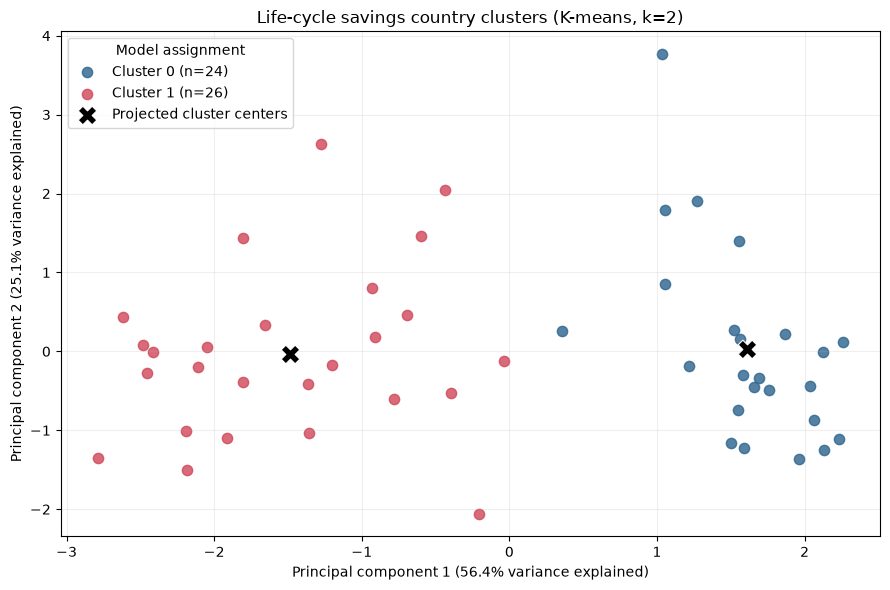

Variance shown in the 2D chart: 81.6 %


In [4]:
# Project the standardized five-feature observations into two principal components for display.
pca = PCA(n_components=2)
coordinates = pca.fit_transform(X_scaled)
plot_df = pd.DataFrame(coordinates, columns=["PC1", "PC2"])
plot_df["cluster"] = cluster_labels

plt.figure(figsize=(9, 6))
colors = ["#2F6690", "#D1495B", "#2A9D8F", "#E9C46A", "#6A4C93"]
for cluster_id in sorted(plot_df["cluster"].unique()):
    mask = plot_df["cluster"] == cluster_id
    plt.scatter(
        plot_df.loc[mask, "PC1"], plot_df.loc[mask, "PC2"],
        s=55, alpha=0.82, color=colors[cluster_id % len(colors)],
        label=f"Cluster {cluster_id} (n={int(mask.sum())})"
    )

# Mark projected K-means centers with a separate symbol.
center_coordinates = pca.transform(kmeans.cluster_centers_)
plt.scatter(center_coordinates[:, 0], center_coordinates[:, 1],
            marker="X", s=180, color="black", edgecolor="white",
            linewidth=0.8, label="Projected cluster centers", zorder=5)
variance = pca.explained_variance_ratio_
plt.title(f"Life-cycle savings country clusters (K-means, k={best_k})")
plt.xlabel(f"Principal component 1 ({variance[0]*100:.1f}% variance explained)")
plt.ylabel(f"Principal component 2 ({variance[1]*100:.1f}% variance explained)")
plt.legend(title="Model assignment")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()
print("Variance shown in the 2D chart:", round(variance.sum() * 100, 1), "%")

## Step 5: AI interpretation prompt and claim

### Prompt 2 (full text)

> Here are my K-means outputs: the silhouette scores for k=2, 3, 4, 5, 6 are 0.4363, 0.4222, 0.3663, 0.3107, and 0.3207, respectively, so the selected solution is k=2. Cluster 0 has 24 countries and raw-unit means sr=7.66, pop15=43.79, pop75=1.12, dpi=332.50, ddpi=3.65. Cluster 1 has 26 countries and raw-unit means sr=11.53, pop15=27.06, pop75=3.38, dpi=1821.46, ddpi=3.86. Overall means are sr=9.6710, pop15=35.0896, pop75=2.2930, dpi=1106.7584, ddpi=3.7576. In 3–4 cautious sentences, describe these profiles and give one specific claim I should verify independently with my own groupby. Do not claim causation.

**AI response / claim to verify:** Cluster 0 has lower average `sr` and `dpi`, a larger `pop15` share, and a smaller `pop75` share than cluster 1. Cluster 1 has higher mean `sr` and `dpi` than the full dataset, and lower mean `pop15`; the output suggests a contrast between younger, lower-income profiles and older, higher-income profiles. This is descriptive and does not show that age structure or income causes savings behavior. I will independently recompute the claim that cluster 1 has higher `sr` and `dpi` and lower `pop15` than the overall means.

## Step 6: Independent verification (my own groupby)

This check recomputes raw-unit means from `df` grouped by the cluster label. It does not reuse a cluster-means table from the AI code. Positive differences mean cluster 1 is above the overall mean; negative differences mean it is below.

In [5]:
# Independent check of the AI claim using raw columns and my own groupby.
verification_data = df.copy()
verification_data["cluster"] = df_clustered["cluster"].to_numpy()
cluster_means_check = verification_data.groupby("cluster")[numeric_cols].mean()
overall_means_check = df[numeric_cols].mean()
verified_cluster = 1

comparison = pd.DataFrame({
    "Cluster 1 mean": cluster_means_check.loc[verified_cluster],
    "Overall mean": overall_means_check,
})
comparison["Cluster 1 minus overall"] = comparison["Cluster 1 mean"] - comparison["Overall mean"]
print(comparison.round(4).to_string())
print("\nCluster 1 country names:")
print(", ".join(verification_data.loc[verification_data["cluster"] == verified_cluster, "Contry"]))

# Verify the three parts of the AI claim.
assert comparison.loc["sr", "Cluster 1 minus overall"] > 0
assert comparison.loc["dpi", "Cluster 1 minus overall"] > 0
assert comparison.loc["pop15", "Cluster 1 minus overall"] < 0
print("\nVerification result: all three directional claims are supported by the groupby means.")

       Cluster 1 mean  Overall mean  Cluster 1 minus overall
sr            11.5308        9.6710                   1.8598
pop15         27.0596       35.0896                  -8.0300
pop75          3.3785        2.2930                   1.0855
dpi         1821.4550     1106.7584                 714.6966
ddpi           3.8562        3.7576                   0.0986

Cluster 1 country names:
Australia, Austria, Belgium, Canada, Denmark, Finland, France, Germany, Greece, Iceland, Ireland, Italy, Japan, Luxembourg, Malta, Norway, Netherlands, New Zealand, Portugal, South Africa, Spain, Sweden, Switzerland, United Kingdom, United States, Uruguay

Verification result: all three directional claims are supported by the groupby means.


### My interpretation and caution (four sentences)

With k=2, cluster 0 contains 24 countries with lower average savings and disposable income, a larger under-15 population share, and a smaller over-75 share. Cluster 1 contains 26 countries with higher average savings and disposable income, fewer young residents proportionally, and more residents over 75; average `ddpi` is fairly similar across the two groups. The split looks like a contrast between lower-income, younger-population profiles and higher-income, older-population profiles in this 1960–1970 country dataset. My caution is that K-means assigns every row to a group using scaled Euclidean distances, and the best silhouette among k=2–6 is only a heuristic, so these are not proven “natural” country types and do not show that one factor causes savings behavior.

## Step 7: Sources and reproducibility

- Dataset description and variable meanings: [R `LifeCycleSavings` documentation](https://stat.ethz.ch/CRAN/web/packages/datasets/refman/datasets.html#LifeCycleSavings).
- Scaling: [scikit-learn `StandardScaler`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html).
- K-means: [scikit-learn `KMeans`](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html).
- Silhouette score: [scikit-learn `silhouette_score`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html).
- PCA: [scikit-learn `PCA`](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html).
- Portfolio repository: https://github.com/roee0910/cs82a-portfolio

